# Notebook 3: Parameter Estimation from Spectral Data (Beer-Lambert)

This notebook demonstrates parameter estimation using spectral (absorbance) data
from kipet's Example 2 dataset.

**Data:** `../../../kipet/examples/example_2/data/Dij.txt`  
Format: 3-column space-separated (time, wavelength, absorbance)  
Size: 300 time points × 100 wavelengths (1610–2600 nm)

**Reaction system:** A → B → C  

**Beer-Lambert model:**  
D[t, λ] = Σ_c C[t, c] · S[λ, c]

where S is the molar absorptivity matrix (unknown) and C are the concentrations.
kipetax jointly estimates k1, k2 (kinetics) and S (spectra).

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kipetax

## Load and explore the spectral data

The D matrix has time as rows and wavelengths as columns.

In [2]:
DATA_FILE = '../../kipet/examples/example_2/data/Dij.txt'

# Load 3-column format: time, wavelength, absorbance
raw = pd.read_csv(DATA_FILE, sep=r'\s+', header=None,
                  names=['time', 'wavelength', 'absorbance'])

# Pivot to D matrix: rows=time, columns=wavelength
D = raw.pivot(index='time', columns='wavelength', values='absorbance')
D.index.name = None
D.columns.name = None

print(f"D matrix shape: {D.shape}  (time points × wavelengths)")
print(f"Time range:       {D.index[0]:.4f} to {D.index[-1]:.4f}")
print(f"Wavelength range: {D.columns[0]:.0f} to {D.columns[-1]:.0f} nm")
print(f"Absorbance range: {D.values.min():.4f} to {D.values.max():.4f}")

D matrix shape: (300, 100)  (time points × wavelengths)
Time range:       0.0000 to 9.9687
Wavelength range: 1610 to 2600 nm
Absorbance range: 0.0587 to 0.1420


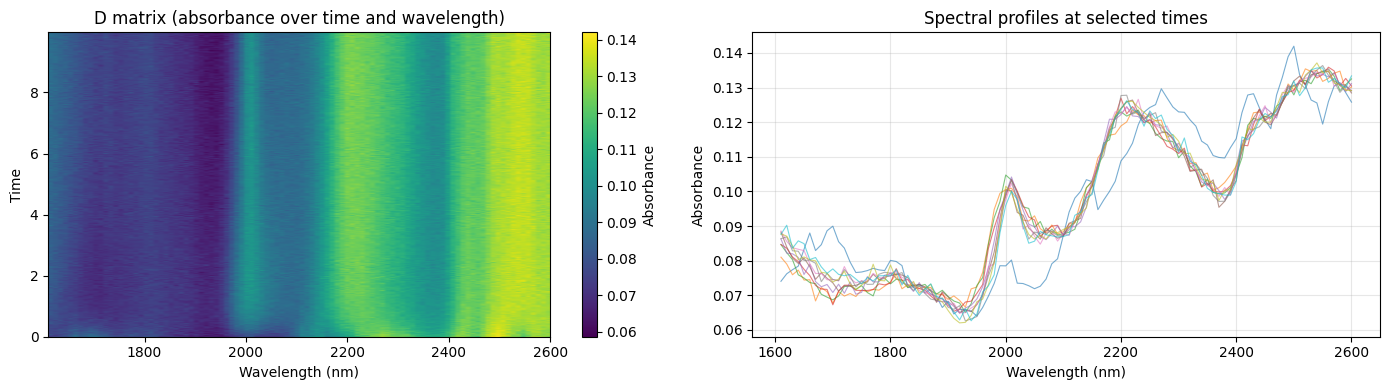

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# D matrix heatmap
ax = axes[0]
im = ax.imshow(D.values, aspect='auto', origin='lower',
               extent=[D.columns[0], D.columns[-1], D.index[0], D.index[-1]],
               cmap='viridis')
plt.colorbar(im, ax=ax, label='Absorbance')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Time')
ax.set_title('D matrix (absorbance over time and wavelength)')

# Spectral profiles at selected times
ax = axes[1]
times_to_plot = D.index[::30]  # every 30th time point
for t in times_to_plot:
    ax.plot(D.columns, D.loc[t], alpha=0.6, linewidth=0.8)
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Absorbance')
ax.set_title('Spectral profiles at selected times')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Subsample the data for tractable computation

The full dataset (300×100) may take several minutes. We subsample to demonstrate the workflow.

In [4]:
# Subsample: take every 6th time point and every 5th wavelength
D_sub = D.iloc[::6, ::5].copy()
print(f"Subsampled D: {D_sub.shape}  (time points × wavelengths)")
print(f"Time points: {D_sub.index.tolist()[:5]} ...")
print(f"Wavelengths: {D_sub.columns.tolist()[:5]} ...")

Subsampled D: (50, 20)  (time points × wavelengths)
Time points: [0.0, 0.2, 0.4001, 0.6001, 0.8002] ...
Wavelengths: [1610.0, 1660.0, 1710.0, 1760.0, 1810.0] ...


## Build the reaction model with spectral data

In [5]:
r1 = kipetax.ReactionModel('spectral-pe')

# Parameters: rate constants with initial guesses from kipet example
k1 = r1.parameter('k1', value=0.3, bounds=(0.0, 5.0))
k2 = r1.parameter('k2', value=1.4, bounds=(0.0, 3.0))

# Components with initial conditions
# A starts at 1, B and C at 0
A = r1.component('A', value=1.0)
B = r1.component('B', value=0.0)
C = r1.component('C', value=0.0)

# ODEs
r1.add_ode('A', -k1 * A)
r1.add_ode('B',  k1 * A - k2 * B)
r1.add_ode('C',  k2 * B)

# Add the subsampled spectral D matrix
r1.add_data(name='spectral', data=D_sub, category='spectral')

# Set discretization
r1.set_discretization(nfe=30, ncp=3)

print("Model built:")
print(f"  Time span: 0 to {D_sub.index[-1]:.2f}")
print(f"  Spectral data: {D_sub.shape}")

Model built:
  Time span: 0 to 9.80
  Spectral data: (50, 20)


## Run parameter estimation

With spectral data, we provide a device (instrument) variance instead of per-component variances.
The optimizer simultaneously fits k1, k2, and the S matrix (molar absorptivities).

In [6]:
# Device variance = expected noise level squared in absorbance units
r1.run_opt(variances={'device': 1e-4})
ro = r1.results_dict['p_estimator']
print(f"Optimization status: {ro.status}")

Parameter estimation complete: status=optimal
  k1                   = 0.356868
  k2                   = 1.65736
Optimization status: optimal


## Results: Kinetic parameters

In [7]:
print("Estimated kinetic parameters:")
for name, val in ro.P.items():
    print(f"  {name} = {val:.4f}")

print(f"\nObjective value: {ro.objective:.4e}")

# Note: kipet reference values are approximately k1≈0.3, k2≈1.4
print("\nkipet reference: k1≈0.3, k2≈1.4")

Estimated kinetic parameters:
  k1 = 0.3569
  k2 = 1.6574

Objective value: 1.8547e+01

kipet reference: k1≈0.3, k2≈1.4


## Results: Concentration profiles

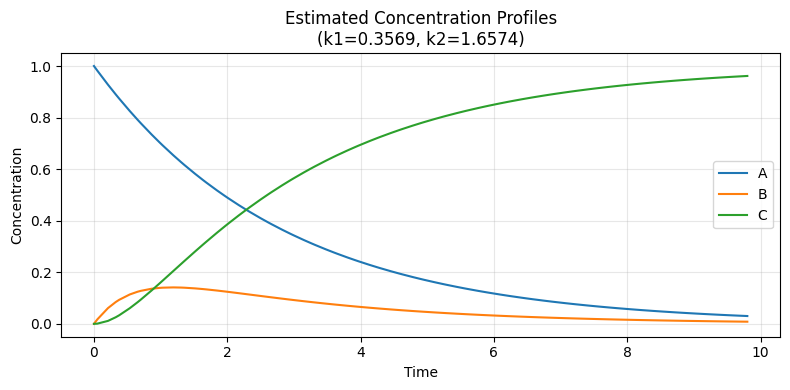

In [8]:
Z = ro.Z  # Concentration profiles

fig, ax = plt.subplots(figsize=(8, 4))
colors = {'A': 'tab:blue', 'B': 'tab:orange', 'C': 'tab:green'}
for comp in Z.columns:
    ax.plot(Z.index, Z[comp], label=comp, color=colors.get(comp))

ax.set_xlabel('Time')
ax.set_ylabel('Concentration')
ax.set_title(f'Estimated Concentration Profiles\n(k1={ro.P["k1"]:.4f}, k2={ro.P["k2"]:.4f})')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Results: Estimated S matrix (molar absorptivities)

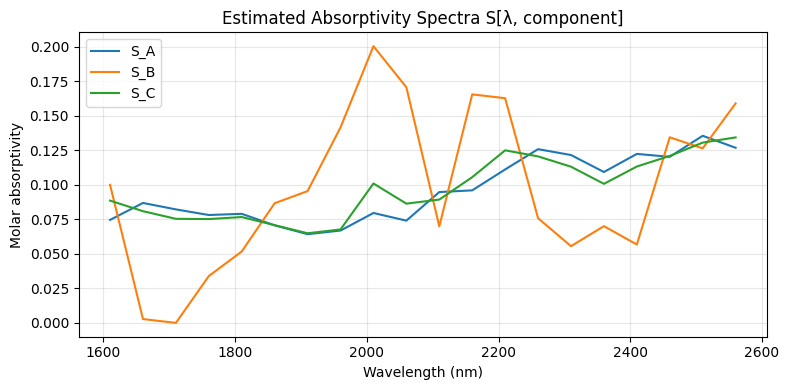

In [9]:
if ro.S is not None:
    fig, ax = plt.subplots(figsize=(8, 4))
    for comp in ro.S.columns:
        ax.plot(ro.S.index, ro.S[comp], label=f'S_{comp}')
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('Molar absorptivity')
    ax.set_title('Estimated Absorptivity Spectra S[λ, component]')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("S matrix not available in results")

## Validate: reconstruct D from C·Sᵀ

D reconstruction RMS error: 1.3621e-03


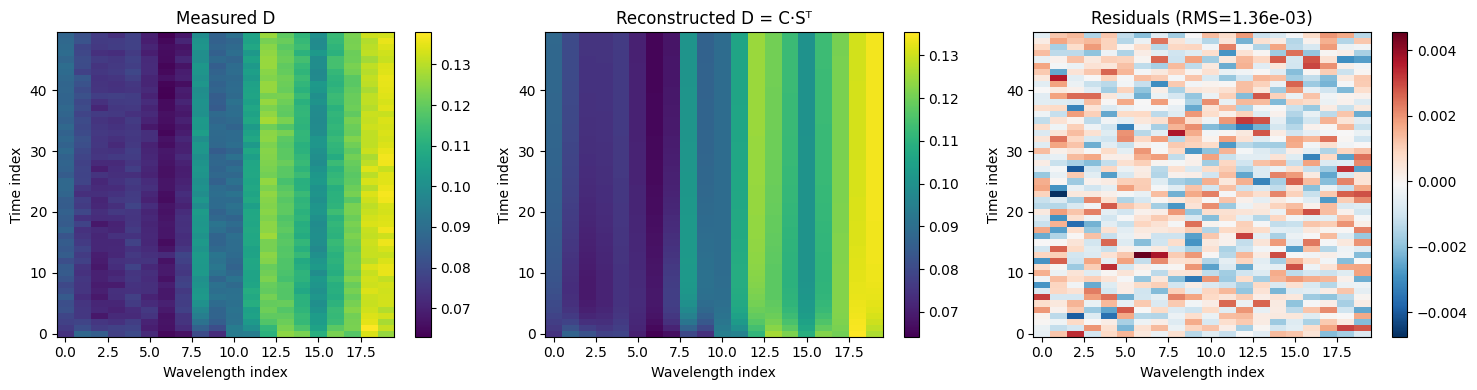

In [10]:
if ro.S is not None:
    # Interpolate Z to the measurement time points
    Z_at_meas = pd.DataFrame(
        {comp: np.interp(D_sub.index, Z.index, Z[comp]) for comp in Z.columns},
        index=D_sub.index
    )

    # Beer-Lambert: D_hat = C @ S^T
    # Z_at_meas: (n_times × n_comps), ro.S: (n_wavelengths × n_comps)
    S_at_wavelengths = ro.S.reindex(D_sub.columns)
    D_hat = Z_at_meas.values @ S_at_wavelengths.values.T
    D_hat_df = pd.DataFrame(D_hat, index=D_sub.index, columns=D_sub.columns)

    residuals = D_sub.values - D_hat_df.values
    rms = np.sqrt(np.mean(residuals**2))
    print(f"D reconstruction RMS error: {rms:.4e}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    im0 = axes[0].imshow(D_sub.values, aspect='auto', origin='lower', cmap='viridis')
    axes[0].set_title('Measured D')
    plt.colorbar(im0, ax=axes[0])

    im1 = axes[1].imshow(D_hat_df.values, aspect='auto', origin='lower', cmap='viridis')
    axes[1].set_title('Reconstructed D = C·Sᵀ')
    plt.colorbar(im1, ax=axes[1])

    im2 = axes[2].imshow(residuals, aspect='auto', origin='lower', cmap='RdBu_r')
    axes[2].set_title(f'Residuals (RMS={rms:.2e})')
    plt.colorbar(im2, ax=axes[2])

    for ax in axes:
        ax.set_xlabel('Wavelength index')
        ax.set_ylabel('Time index')

    plt.tight_layout()
    plt.show()